In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ahmedabad = pd.read_csv("C:\\Users\\hp\\OneDrive\\Desktop\\ml_project\\ahmedabad.csv")
ahmedabad.head()

,Unnamed: 0,company_name,company_rating,other_data
0,0,Zydus Lifesciences,4.2,"Pharma , 10k-50k Employees , Public , 72 years..."
1,1,Intas Pharmaceuticals,4.2,"Pharma , 10k-50k Employees , Fortune India 500..."
2,2,Vodafone Idea,4.2,"Telecom , 5k-10k Employees , Public , 6 years ..."
3,3,TTEC India,3.8,"BPO , 1k-5k Employees , Public , 40 years old ..."
4,4,Cadila Pharmaceuticals,3.6,"Pharma , 5k-10k Employees , Public , 73 years ..."


In [3]:
ahmedabad.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      10000 non-null  int64  
 1   company_name    10000 non-null  str    
 2   company_rating  9980 non-null   float64
 3   other_data      10000 non-null  str    
dtypes: float64(1), int64(1), str(2)
memory usage: 312.6 KB


In [4]:
ahmedabad['other_data'].head()

0    Pharma , 10k-50k Employees , Public , 72 years...
1    Pharma , 10k-50k Employees , Fortune India 500...
2    Telecom , 5k-10k Employees , Public , 6 years ...
3    BPO , 1k-5k Employees , Public , 40 years old ...
4    Pharma , 5k-10k Employees , Public , 73 years ...
Name: other_data, dtype: str

In [5]:
def split_column(text):
    part = [txt.strip() for txt in text.split(",")]
    columns = {
        'industry':None,
        'employes':None,
        'type':None,
        'age':None,
        'location':None
    }
    if part:
        columns['location'] = part.pop()
    types = ["Public", "Startup", "Indian Unicorn", "Government",
                 "Central", "State", "Conglomerate","Forbes Global 2000", "Fortune India 500",'MNC']
    tf=[]
    for i in part:
        if 'Employees' in i:
            columns['employes']=i
        elif 'years old' in i:
            columns['age'] = i
        elif i in types:
            tf.append(i)
        else:
            columns['industry'] = i
    columns['type'] = ", ".join(tf) if tf else None
    return pd.Series(columns)

In [6]:
clean = ahmedabad['other_data'].apply(split_column)
ahmedabad=pd.concat([ahmedabad[['company_name','company_rating']],clean],axis=1)
ahmedabad

,company_name,company_rating,industry,employes,type,age,location
0,Zydus Lifesciences,4.2,Pharma,10k-50k Employees,Public,72 years old,Ahmedabad +152 more
1,Intas Pharmaceuticals,4.2,Pharma,10k-50k Employees,Fortune India 500,47 years old,Ahmedabad +116 more
2,Vodafone Idea,4.2,Telecom,5k-10k Employees,Public,6 years old,Ahmedabad +637 more
3,TTEC India,3.8,BPO,1k-5k Employees,Public,40 years old,Ahmedabad +24 more
4,Cadila Pharmaceuticals,3.6,Pharma,5k-10k Employees,Public,73 years old,Ahmedabad +114 more
...,...,...,...,...,...,...,...
9995,Aadharshila School,4.9,Education & Training,11-50 Employees,NaN,NaN,Ahmedabad +1 more
9996,Adroit Valuations,3.5,Accounting & Auditing,201-500 Employees,NaN,NaN,Ahmedabad +7 more
9997,Meru Consultants,1.0,NaN,NaN,NaN,30 years old,Ahmedabad
9998,Excare Laboratories,4.0,NaN,NaN,NaN,NaN,Ahmedabad


In [7]:
bangalore = pd.read_csv("C:\\Users\\hp\\OneDrive\\Desktop\\ml_project\\bangalore.csv")
bangalore.head()

,Unnamed: 0,company_name,company_rating,other_data
0,0,TCS,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."
1,1,Accenture,4.0,"IT Services & Consulting , 1 Lakh+ Employees ,..."
2,2,Cognizant,3.9,"IT Services & Consulting , 1 Lakh+ Employees ,..."
3,3,Wipro,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."
4,4,Capgemini,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."


In [8]:
bangalore.info()

<class 'pandas.DataFrame'>
RangeIndex: 8560 entries, 0 to 8559
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      8560 non-null   int64  
 1   company_name    8560 non-null   str    
 2   company_rating  8560 non-null   float64
 3   other_data      8560 non-null   str    
dtypes: float64(1), int64(1), str(2)
memory usage: 267.6 KB


In [9]:
bangalore['other_data'].head()

0    IT Services & Consulting , 1 Lakh+ Employees ,...
1    IT Services & Consulting , 1 Lakh+ Employees ,...
2    IT Services & Consulting , 1 Lakh+ Employees ,...
3    IT Services & Consulting , 1 Lakh+ Employees ,...
4    IT Services & Consulting , 1 Lakh+ Employees ,...
Name: other_data, dtype: str

In [10]:
clean2 = bangalore['other_data'].apply(split_column)
bangalore = pd.concat([bangalore[['company_name','company_rating']],clean2],axis=1)
bangalore

,company_name,company_rating,industry,employes,type,age,location
0,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56 years old,Mumbai +349 more
1,Accenture,4.0,IT Services & Consulting,1 Lakh+ Employees,Public,35 years old,Dublin +181 more
2,Cognizant,3.9,IT Services & Consulting,1 Lakh+ Employees,Forbes Global 2000,30 years old,Teaneck. New Jersey. +169 more
3,Wipro,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,79 years old,Bangalore/Bengaluru +272 more
4,Capgemini,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,57 years old,Paris +142 more
...,...,...,...,...,...,...,...
8555,Amazon,4.1,Internet,1 Lakh+ Employees,Public,30 years old,Seattle +455 more
8556,IBM,4.1,IT Services & Consulting,1 Lakh+ Employees,Public,113 years old,Armonk +149 more
8557,Reliance Retail,4.0,Retail,1 Lakh+ Employees,NaN,18 years old,Navi Mumbai +1013 more
8558,HDB Financial Services,4.0,NBFC,1 Lakh+ Employees,NaN,17 years old,Ahmedabad +959 more


In [11]:
chennai = pd.read_csv("C:\\Users\\hp\\OneDrive\\Desktop\\ml_project\\chennai.csv")
chennai.head()

,Unnamed: 0,company_name,company_rating,other_data
0,0,TCS,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."
1,1,Cognizant,3.9,"IT Services & Consulting , 1 Lakh+ Employees ,..."
2,2,HCLTech,3.7,"IT Services & Consulting , 1 Lakh+ Employees ,..."
3,3,Accenture,4.0,"IT Services & Consulting , 1 Lakh+ Employees ,..."
4,4,Wipro,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."


In [12]:
chennai.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      10000 non-null  int64  
 1   company_name    10000 non-null  str    
 2   company_rating  9993 non-null   float64
 3   other_data      10000 non-null  str    
dtypes: float64(1), int64(1), str(2)
memory usage: 312.6 KB


In [13]:
chennai['other_data'].head()

0    IT Services & Consulting , 1 Lakh+ Employees ,...
1    IT Services & Consulting , 1 Lakh+ Employees ,...
2    IT Services & Consulting , 1 Lakh+ Employees ,...
3    IT Services & Consulting , 1 Lakh+ Employees ,...
4    IT Services & Consulting , 1 Lakh+ Employees ,...
Name: other_data, dtype: str

In [14]:
clean3 = chennai['other_data'].apply(split_column)
chennai = pd.concat([chennai[['company_name','company_rating']],clean3],axis=1)
chennai

,company_name,company_rating,industry,employes,type,age,location
0,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56 years old,Chennai +349 more
1,Cognizant,3.9,IT Services & Consulting,1 Lakh+ Employees,Forbes Global 2000,30 years old,Chennai +169 more
2,HCLTech,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,33 years old,Chennai +184 more
3,Accenture,4.0,IT Services & Consulting,1 Lakh+ Employees,Public,35 years old,Chennai +181 more
4,Wipro,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,79 years old,Chennai +272 more
...,...,...,...,...,...,...,...
9995,Thulirsoftware Technologies,4.4,NaN,NaN,NaN,NaN,Chennai +1 more
9996,B-FLUX MANAGEMENT SERVICES,2.7,NaN,11-50 Employees (Global),NaN,13 years old,Chennai +1 more
9997,Nexus,4.1,Internet,NaN,NaN,24 years old,Chennai +12 more
9998,Bharathi Matriculation Higher Secondary School,3.3,Education & Training,11-50 Employees,NaN,NaN,Chennai +5 more


In [15]:
gurugram = pd.read_csv("C:\\Users\\hp\\OneDrive\\Desktop\\ml_project\\gurugram.csv")
gurugram.head()

,Unnamed: 0,company_name,company_rating,other_data
0,0,TCS,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."
1,1,Accenture,4.0,"IT Services & Consulting , 1 Lakh+ Employees ,..."
2,2,Cognizant,3.9,"IT Services & Consulting , 1 Lakh+ Employees ,..."
3,3,Wipro,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."
4,4,Capgemini,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."


In [16]:
gurugram.info()

<class 'pandas.DataFrame'>
RangeIndex: 8300 entries, 0 to 8299
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      8300 non-null   int64  
 1   company_name    8300 non-null   str    
 2   company_rating  8300 non-null   float64
 3   other_data      8300 non-null   str    
dtypes: float64(1), int64(1), str(2)
memory usage: 259.5 KB


In [17]:
gurugram['other_data'].head()

0    IT Services & Consulting , 1 Lakh+ Employees ,...
1    IT Services & Consulting , 1 Lakh+ Employees ,...
2    IT Services & Consulting , 1 Lakh+ Employees ,...
3    IT Services & Consulting , 1 Lakh+ Employees ,...
4    IT Services & Consulting , 1 Lakh+ Employees ,...
Name: other_data, dtype: str

In [18]:
clean4 = gurugram['other_data'].apply(split_column)
gurugram = pd.concat([gurugram[['company_name','company_rating']],clean4],axis=1)
gurugram

,company_name,company_rating,industry,employes,type,age,location
0,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56 years old,Mumbai +349 more
1,Accenture,4.0,IT Services & Consulting,1 Lakh+ Employees,Public,35 years old,Dublin +181 more
2,Cognizant,3.9,IT Services & Consulting,1 Lakh+ Employees,Forbes Global 2000,30 years old,Teaneck. New Jersey. +169 more
3,Wipro,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,79 years old,Bangalore/Bengaluru +272 more
4,Capgemini,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,57 years old,Paris +142 more
...,...,...,...,...,...,...,...
8295,Amazon,4.1,Internet,1 Lakh+ Employees,Public,30 years old,Seattle +455 more
8296,IBM,4.1,IT Services & Consulting,1 Lakh+ Employees,Public,113 years old,Armonk +149 more
8297,Reliance Retail,4.0,Retail,1 Lakh+ Employees,NaN,18 years old,Navi Mumbai +1013 more
8298,HDB Financial Services,4.0,NBFC,1 Lakh+ Employees,NaN,17 years old,Ahmedabad +959 more


In [19]:
hyderabad = pd.read_csv("C:\\Users\\hp\\OneDrive\\Desktop\\ml_project\\hyderabad.csv")
hyderabad.head()

,Unnamed: 0,company_name,company_rating,other_data
0,0,TCS,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."
1,1,Cognizant,3.9,"IT Services & Consulting , 1 Lakh+ Employees ,..."
2,2,Wipro,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."
3,3,Genpact,3.9,"IT Services & Consulting , 1 Lakh+ Employees ,..."
4,4,Accenture,4.0,"IT Services & Consulting , 1 Lakh+ Employees ,..."


In [20]:
hyderabad.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      10000 non-null  int64  
 1   company_name    10000 non-null  str    
 2   company_rating  9990 non-null   float64
 3   other_data      10000 non-null  str    
dtypes: float64(1), int64(1), str(2)
memory usage: 312.6 KB


In [21]:
clean5 = hyderabad['other_data'].apply(split_column)
hyderabad = pd.concat([hyderabad[['company_name','company_rating']],clean5],axis=1)
hyderabad

,company_name,company_rating,industry,employes,type,age,location
0,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56 years old,Hyderabad / Secunderabad +349 more
1,Cognizant,3.9,IT Services & Consulting,1 Lakh+ Employees,Forbes Global 2000,30 years old,Hyderabad / Secunderabad +169 more
2,Wipro,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,79 years old,Hyderabad / Secunderabad +272 more
3,Genpact,3.9,IT Services & Consulting,1 Lakh+ Employees,Public,27 years old,Hyderabad / Secunderabad +112 more
4,Accenture,4.0,IT Services & Consulting,1 Lakh+ Employees,Public,35 years old,Hyderabad / Secunderabad +181 more
...,...,...,...,...,...,...,...
9995,The White Teak Company,3.7,NaN,201-500 Employees,NaN,8 years old,Hyderabad / Secunderabad +7 more
9996,Bridgegap Consultants,3.9,NaN,11-50 Employees,NaN,10 years old,Hyderabad / Secunderabad +1 more
9997,Advanced Medtech Solutions,3.6,Medical Equipment,51-200 Employees,NaN,11 years old,Hyderabad / Secunderabad +15 more
9998,I.B.S.,3.7,IT Services & Consulting,NaN,NaN,NaN,Hyderabad / Secunderabad +13 more


In [22]:
indore = pd.read_csv("C:\\Users\\hp\\OneDrive\\Desktop\\ml_project\\indore.csv")
indore.head()

,Unnamed: 0,company_name,company_rating,other_data
0,0,Teleperformance,3.8,"BPO , 50k-1 Lakh Employees , Forbes Global 200..."
1,1,TCS,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."
2,2,Cipla,4.1,"Pharma , 10k-50k Employees , Public , 89 years..."
3,3,TaskUs,3.5,"BPO , 5k-10k Employees , 16 years old , Indore..."
4,4,ICICI Bank,4.0,"Banking , 1 Lakh+ Employees , Public , 30 year..."


In [23]:
indore.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      10000 non-null  int64  
 1   company_name    10000 non-null  str    
 2   company_rating  9983 non-null   float64
 3   other_data      10000 non-null  str    
dtypes: float64(1), int64(1), str(2)
memory usage: 312.6 KB


In [24]:
indore['other_data'].head()

0    BPO , 50k-1 Lakh Employees , Forbes Global 200...
1    IT Services & Consulting , 1 Lakh+ Employees ,...
2    Pharma , 10k-50k Employees , Public , 89 years...
3    BPO , 5k-10k Employees , 16 years old , Indore...
4    Banking , 1 Lakh+ Employees , Public , 30 year...
Name: other_data, dtype: str

In [25]:
clean6 = indore['other_data'].apply(split_column)
indore = pd.concat([indore[['company_name','company_rating']],clean6],axis=1)
indore

,company_name,company_rating,industry,employes,type,age,location
0,Teleperformance,3.8,BPO,50k-1 Lakh Employees,Forbes Global 2000,46 years old,Indore +192 more
1,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56 years old,Indore +349 more
2,Cipla,4.1,Pharma,10k-50k Employees,Public,89 years old,Indore +239 more
3,TaskUs,3.5,BPO,5k-10k Employees,NaN,16 years old,Indore +24 more
4,ICICI Bank,4.0,Banking,1 Lakh+ Employees,Public,30 years old,Indore +1295 more
...,...,...,...,...,...,...,...
9995,Kairos Hygiene,5.0,NaN,NaN,NaN,NaN,Indore
9996,Jenburkt Pharmaceuticals,4.3,Pharma,501-1k Employees,Public,39 years old,Indore +11 more
9997,Beri Udyog,4.0,Industrial Machinery,201-500 Employees,NaN,46 years old,Indore +13 more
9998,Honda Cars,4.4,Automobile,5k-10k Employees,Fortune India 500,29 years old,Indore +91 more


In [26]:
jaipur = pd.read_csv("C:\\Users\\hp\\OneDrive\\Desktop\\ml_project\\jaipur.csv")
jaipur.head()

,Unnamed: 0,company_name,company_rating,other_data
0,0,AU Small Finance Bank,4.4,"Banking , 10k-50k Employees , Fortune India 50..."
1,1,Teleperformance,3.8,"BPO , 50k-1 Lakh Employees , Forbes Global 200..."
2,2,Genpact,3.9,"IT Services & Consulting , 1 Lakh+ Employees ,..."
3,3,ICICI Bank,4.0,"Banking , 1 Lakh+ Employees , Public , 30 year..."
4,4,HDFC Bank,4.0,"Banking , 1 Lakh+ Employees , Public , 30 year..."


In [27]:
jaipur.info()

<class 'pandas.DataFrame'>
RangeIndex: 8600 entries, 0 to 8599
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      8600 non-null   int64  
 1   company_name    8600 non-null   str    
 2   company_rating  8573 non-null   float64
 3   other_data      8600 non-null   str    
dtypes: float64(1), int64(1), str(2)
memory usage: 268.9 KB


In [28]:
jaipur['other_data'].head()

0    Banking , 10k-50k Employees , Fortune India 50...
1    BPO , 50k-1 Lakh Employees , Forbes Global 200...
2    IT Services & Consulting , 1 Lakh+ Employees ,...
3    Banking , 1 Lakh+ Employees , Public , 30 year...
4    Banking , 1 Lakh+ Employees , Public , 30 year...
Name: other_data, dtype: str

In [29]:
clean7 = jaipur['other_data'].apply(split_column)
jaipur = pd.concat([jaipur[['company_name','company_rating']],clean7],axis=1)
jaipur

,company_name,company_rating,industry,employes,type,age,location
0,AU Small Finance Bank,4.4,Banking,10k-50k Employees,Fortune India 500,28 years old,Jaipur +409 more
1,Teleperformance,3.8,BPO,50k-1 Lakh Employees,Forbes Global 2000,46 years old,Jaipur +192 more
2,Genpact,3.9,IT Services & Consulting,1 Lakh+ Employees,Public,27 years old,Jaipur +112 more
3,ICICI Bank,4.0,Banking,1 Lakh+ Employees,Public,30 years old,Jaipur +1295 more
4,HDFC Bank,4.0,Banking,1 Lakh+ Employees,Public,30 years old,Jaipur +1560 more
...,...,...,...,...,...,...,...
8595,Between The Brews,5.0,NaN,NaN,NaN,NaN,Jaipur
8596,National Helpline for Senior Citizens,4.2,NaN,NaN,NaN,NaN,Agartala +5 more
8597,Aash biotech,3.7,NaN,NaN,NaN,NaN,Jaipur +2 more
8598,Jain Clave Polytech,4.0,NaN,NaN,NaN,NaN,Jaipur


In [30]:
mumbai = pd.read_csv("C:\\Users\\hp\\OneDrive\\Desktop\\ml_project\\mumbai.csv")
mumbai.head()

,Unnamed: 0,company_name,company_rating,other_data
0,0,TCS,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."
1,1,Kotak Mahindra Bank,3.9,"Banking , 50k-1 Lakh Employees , Public , 21 y..."
2,2,Accenture,4.0,"IT Services & Consulting , 1 Lakh+ Employees ,..."
3,3,ICICI Bank,4.0,"Banking , 1 Lakh+ Employees , Public , 30 year..."
4,4,Capgemini,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."


In [31]:
mumbai.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      10000 non-null  int64  
 1   company_name    10000 non-null  str    
 2   company_rating  9995 non-null   float64
 3   other_data      10000 non-null  str    
dtypes: float64(1), int64(1), str(2)
memory usage: 312.6 KB


In [32]:
mumbai['other_data'].head()

0    IT Services & Consulting , 1 Lakh+ Employees ,...
1    Banking , 50k-1 Lakh Employees , Public , 21 y...
2    IT Services & Consulting , 1 Lakh+ Employees ,...
3    Banking , 1 Lakh+ Employees , Public , 30 year...
4    IT Services & Consulting , 1 Lakh+ Employees ,...
Name: other_data, dtype: str

In [33]:
clean8 = mumbai['other_data'].apply(split_column)
mumbai = pd.concat([mumbai[['company_name','company_rating']],clean8],axis=1)
mumbai

,company_name,company_rating,industry,employes,type,age,location
0,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56 years old,Mumbai +349 more
1,Kotak Mahindra Bank,3.9,Banking,50k-1 Lakh Employees,Public,21 years old,Mumbai +573 more
2,Accenture,4.0,IT Services & Consulting,1 Lakh+ Employees,Public,35 years old,Mumbai +181 more
3,ICICI Bank,4.0,Banking,1 Lakh+ Employees,Public,30 years old,Mumbai +1295 more
4,Capgemini,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,57 years old,Mumbai +142 more
...,...,...,...,...,...,...,...
9995,Nvizion Solutions,4.5,Internet,51-200 Employees,NaN,NaN,Mumbai +1 more
9996,Natvarlal Vepari & Co.,4.4,NaN,NaN,NaN,NaN,Mumbai +1 more
9997,JetSynthesys,2.7,IT Services & Consulting,201-500 Employees,Startup,12 years old,Mumbai +2 more
9998,Zee News,3.8,Broadcasting,10k-50k Employees,Public,25 years old,Mumbai +11 more


In [34]:
noida = pd.read_csv("C:\\Users\\hp\\OneDrive\\Desktop\\ml_project\\noida.csv")
noida.head()

,Unnamed: 0,company_name,company_rating,other_data
0,0,iEnergizer,4.7,"BPO , 10k-50k Employees , 24 years old , Noida..."
1,1,HCLTech,3.7,"IT Services & Consulting , 1 Lakh+ Employees ,..."
2,2,Genpact,3.9,"IT Services & Consulting , 1 Lakh+ Employees ,..."
3,3,Tech Mahindra,3.7,"IT Services & Consulting , 1 Lakh+ Employees ,..."
4,4,TCS,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."


In [35]:
noida.info()

<class 'pandas.DataFrame'>
RangeIndex: 9120 entries, 0 to 9119
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      9120 non-null   int64  
 1   company_name    9120 non-null   str    
 2   company_rating  9115 non-null   float64
 3   other_data      9120 non-null   str    
dtypes: float64(1), int64(1), str(2)
memory usage: 285.1 KB


In [36]:
noida['other_data'].head()

0    BPO , 10k-50k Employees , 24 years old , Noida...
1    IT Services & Consulting , 1 Lakh+ Employees ,...
2    IT Services & Consulting , 1 Lakh+ Employees ,...
3    IT Services & Consulting , 1 Lakh+ Employees ,...
4    IT Services & Consulting , 1 Lakh+ Employees ,...
Name: other_data, dtype: str

In [37]:
clean9 = noida['other_data'].apply(split_column)
noida = pd.concat([noida[['company_name','company_rating']],clean9],axis=1)
noida

,company_name,company_rating,industry,employes,type,age,location
0,iEnergizer,4.7,BPO,10k-50k Employees,NaN,24 years old,Noida +31 more
1,HCLTech,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,33 years old,Noida +184 more
2,Genpact,3.9,IT Services & Consulting,1 Lakh+ Employees,Public,27 years old,New York +112 more
3,Tech Mahindra,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,38 years old,Pune +269 more
4,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56 years old,Mumbai +349 more
...,...,...,...,...,...,...,...
9115,STITCHED TEXTILES,3.5,NaN,NaN,NaN,NaN,Noida +2 more
9116,Zindagi Technologies,3.8,NaN,51-200 Employees,NaN,NaN,Noida +2 more
9117,Ritvi Innovations,1.6,NaN,NaN,NaN,NaN,Noida
9118,Clickvaults,4.3,NaN,NaN,NaN,NaN,Noida


In [38]:
pune = pd.read_csv("C:\\Users\\hp\\OneDrive\\Desktop\\ml_project\\noida.csv")
pune.head()

,Unnamed: 0,company_name,company_rating,other_data
0,0,iEnergizer,4.7,"BPO , 10k-50k Employees , 24 years old , Noida..."
1,1,HCLTech,3.7,"IT Services & Consulting , 1 Lakh+ Employees ,..."
2,2,Genpact,3.9,"IT Services & Consulting , 1 Lakh+ Employees ,..."
3,3,Tech Mahindra,3.7,"IT Services & Consulting , 1 Lakh+ Employees ,..."
4,4,TCS,3.8,"IT Services & Consulting , 1 Lakh+ Employees ,..."


In [39]:
pune.info()

<class 'pandas.DataFrame'>
RangeIndex: 9120 entries, 0 to 9119
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      9120 non-null   int64  
 1   company_name    9120 non-null   str    
 2   company_rating  9115 non-null   float64
 3   other_data      9120 non-null   str    
dtypes: float64(1), int64(1), str(2)
memory usage: 285.1 KB


In [40]:
pune['other_data'].head()

0    BPO , 10k-50k Employees , 24 years old , Noida...
1    IT Services & Consulting , 1 Lakh+ Employees ,...
2    IT Services & Consulting , 1 Lakh+ Employees ,...
3    IT Services & Consulting , 1 Lakh+ Employees ,...
4    IT Services & Consulting , 1 Lakh+ Employees ,...
Name: other_data, dtype: str

In [41]:
clean10 = pune['other_data'].apply(split_column)
pune = pd.concat([pune[['company_name','company_rating']],clean10],axis=1)
pune

,company_name,company_rating,industry,employes,type,age,location
0,iEnergizer,4.7,BPO,10k-50k Employees,NaN,24 years old,Noida +31 more
1,HCLTech,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,33 years old,Noida +184 more
2,Genpact,3.9,IT Services & Consulting,1 Lakh+ Employees,Public,27 years old,New York +112 more
3,Tech Mahindra,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,38 years old,Pune +269 more
4,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56 years old,Mumbai +349 more
...,...,...,...,...,...,...,...
9115,STITCHED TEXTILES,3.5,NaN,NaN,NaN,NaN,Noida +2 more
9116,Zindagi Technologies,3.8,NaN,51-200 Employees,NaN,NaN,Noida +2 more
9117,Ritvi Innovations,1.6,NaN,NaN,NaN,NaN,Noida
9118,Clickvaults,4.3,NaN,NaN,NaN,NaN,Noida


In [42]:
dflist = [pune,mumbai,noida,jaipur,indore,hyderabad,gurugram,chennai,bangalore,ahmedabad]

In [43]:
df = pd.concat(dflist,ignore_index=True)
df

,company_name,company_rating,industry,employes,type,age,location
0,iEnergizer,4.7,BPO,10k-50k Employees,NaN,24 years old,Noida +31 more
1,HCLTech,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,33 years old,Noida +184 more
2,Genpact,3.9,IT Services & Consulting,1 Lakh+ Employees,Public,27 years old,New York +112 more
3,Tech Mahindra,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,38 years old,Pune +269 more
4,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56 years old,Mumbai +349 more
...,...,...,...,...,...,...,...
93695,Aadharshila School,4.9,Education & Training,11-50 Employees,NaN,NaN,Ahmedabad +1 more
93696,Adroit Valuations,3.5,Accounting & Auditing,201-500 Employees,NaN,NaN,Ahmedabad +7 more
93697,Meru Consultants,1.0,NaN,NaN,NaN,30 years old,Ahmedabad
93698,Excare Laboratories,4.0,NaN,NaN,NaN,NaN,Ahmedabad


In [44]:
df.duplicated().sum()

np.int64(37629)

In [45]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

In [46]:
df.duplicated().sum()

np.int64(0)

In [47]:
(df.isnull().sum()/df.shape[0])*100

company_name       0.000000
company_rating     0.135542
industry          44.065560
employes          34.814788
type              84.373384
age               49.119866
location           0.000000
dtype: float64

In [48]:
df.head()

,company_name,company_rating,industry,employes,type,age,location
0,iEnergizer,4.7,BPO,10k-50k Employees,NaN,24 years old,Noida +31 more
1,HCLTech,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,33 years old,Noida +184 more
2,Genpact,3.9,IT Services & Consulting,1 Lakh+ Employees,Public,27 years old,New York +112 more
3,Tech Mahindra,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,38 years old,Pune +269 more
4,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56 years old,Mumbai +349 more


In [49]:
df['location'] = df['location'].str.split('+').str[0].str.strip().str.lower()

In [50]:
df.head()

,company_name,company_rating,industry,employes,type,age,location
0,iEnergizer,4.7,BPO,10k-50k Employees,NaN,24 years old,noida
1,HCLTech,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,33 years old,noida
2,Genpact,3.9,IT Services & Consulting,1 Lakh+ Employees,Public,27 years old,new york
3,Tech Mahindra,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,38 years old,pune
4,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56 years old,mumbai


In [51]:
df['age'] = df['age'].str.lower().str.replace("years old","").str.strip()

In [52]:
df.head()

,company_name,company_rating,industry,employes,type,age,location
0,iEnergizer,4.7,BPO,10k-50k Employees,NaN,24,noida
1,HCLTech,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,33,noida
2,Genpact,3.9,IT Services & Consulting,1 Lakh+ Employees,Public,27,new york
3,Tech Mahindra,3.7,IT Services & Consulting,1 Lakh+ Employees,Public,38,pune
4,TCS,3.8,IT Services & Consulting,1 Lakh+ Employees,Public,56,mumbai


In [53]:
df['type'] = df['type'].str.lower().str.strip()

In [54]:
df['employes'] = df['employes'].str.replace("Employees","").str.replace('(Global)',"").str.strip()

In [55]:
df['industry'] = df['industry'].str.strip()

In [56]:
df['age'] = pd.to_numeric(df['age'],errors='coerce')

In [57]:
df.head()

,company_name,company_rating,industry,employes,type,age,location
0,iEnergizer,4.7,BPO,10k-50k,NaN,24.0,noida
1,HCLTech,3.7,IT Services & Consulting,1 Lakh+,public,33.0,noida
2,Genpact,3.9,IT Services & Consulting,1 Lakh+,public,27.0,new york
3,Tech Mahindra,3.7,IT Services & Consulting,1 Lakh+,public,38.0,pune
4,TCS,3.8,IT Services & Consulting,1 Lakh+,public,56.0,mumbai


In [58]:
df.isnull().sum()

company_name          0
company_rating       76
industry          24708
employes          19521
type              47309
age               27542
location              0
dtype: int64

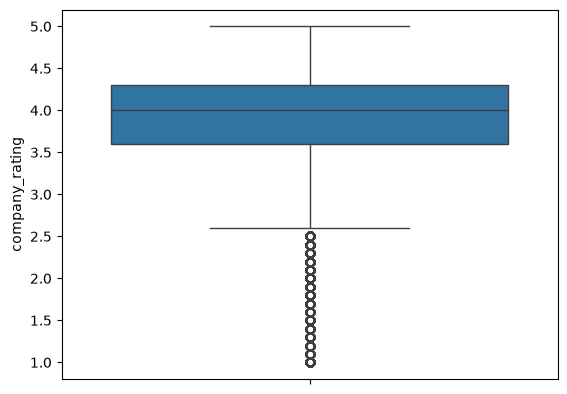

In [59]:
sns.boxplot(df['company_rating'])
plt.show()

In [60]:
df['company_rating'] = df['company_rating'].fillna(df['company_rating'].median())

In [61]:
df.isnull().sum()

company_name          0
company_rating        0
industry          24708
employes          19521
type              47309
age               27542
location              0
dtype: int64

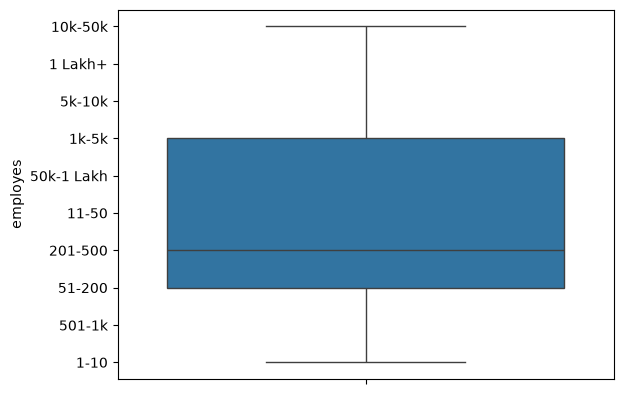

In [62]:
sns.boxplot(df['employes'])
plt.show()

In [63]:
df['employes'] = df['employes'].fillna(df['employes'].mode()[0])

In [64]:
df.isnull().sum()

company_name          0
company_rating        0
industry          24708
employes              0
type              47309
age               27542
location              0
dtype: int64

In [65]:
df['age'] = df['age'].fillna("--")
df['type'] = df['type'].fillna("other")
df['industry'] = df['industry'].fillna("other")

In [66]:
df.to_csv('company_data2.csv',index = False)

In [ ]:
for i in 